# Análise de Estabilidade Linear da Convecção Térmica e MRI em Discos de Acreção
- PET - Física
- Petiana: Ylana Karolina Santos Lopes
- Data: 02 de Outubro de 2026

$\quad$ O objetivo deste `Notebook` é fazer uma análise linear da estabilidade em um disco de acreção quanda há convecção e instabilidade magnetorotacional atuando nele, analisando o comportamento dos modos de oscilação encontrados. Introduziremos conceitos base de magnetohidrodinâmica para sustentar a explicação da instabilidade e como a convecção entra nesse contexto. Seguiremos a seguinte estrutura:

1. Introdução: O Problema com Transporte de Momento Angular;
2. Aproximação de Caixa de Cisalhamento;
3. Análise Linear de Estabilidade;
4. Classificação dos Modos de Oscilação;
5. Mapa de Estabilidade;
6. Conclusões.


### Nota de Agradecimento

---
O conteúdo deste `Notebook` foi parte do resultado do Programa de Verão no HZDR, sob a supervisão do Dr. Ashish Mishra que idealizou o projeto e o orientou.

---

### Importando bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import warnings

# Suppress runtime warnings for taking the square root of negative numbers
warnings.filterwarnings('ignore', category=RuntimeWarning)

### Detalhes das bibliotecas


In [2]:
%load_ext version_information
%version_information matplotlib, numpy

Software versions
Python 3.11.8 64bit [MSC v.1916 64 bit (AMD64)]
IPython 8.20.0
OS Windows 10 10.0.26200 SP0
matplotlib 3.8.0
numpy 1.26.4
Fri Oct 23 00:26:43 2026 Hora oficial do Brasil

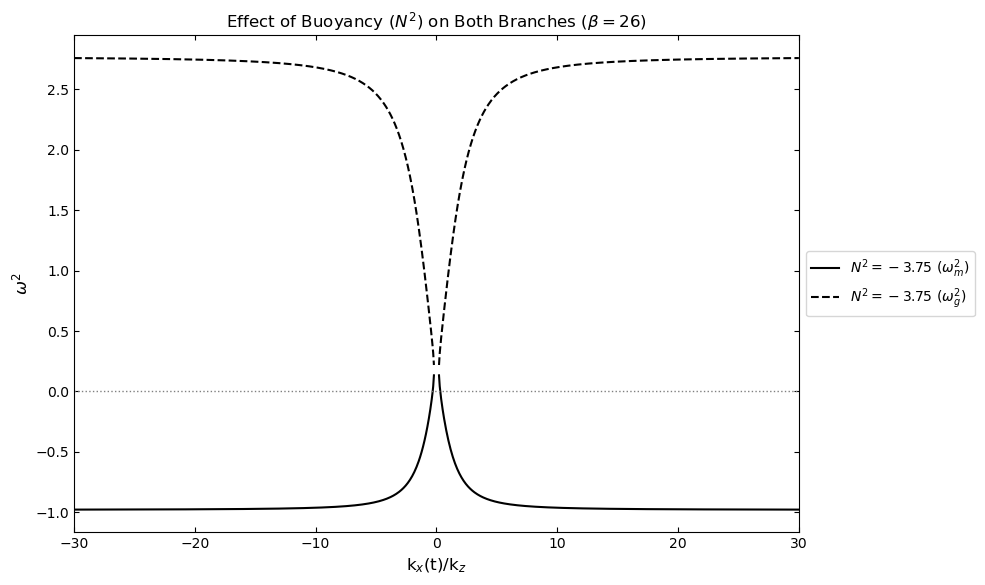

In [2]:
def calculate_w2(N2, beta, q=1.5, kz=6.0, ky_ratio=2.0):
    ky = ky_ratio * kz
    kx_kz = np.linspace(-30, 30, 1000)
    kx = kx_kz * kz
    k2 = kx**2 + ky**2 + kz**2
    
    a1 = (N2 * (ky**2 + kx**2) / k2 
          + 2 * (2 - q) * (kz**2) / k2 
          + 4 * kz**2 / beta 
          - 2 * q * (ky**2) / k2)
    
    a2 = (2 * q * N2 * (ky**2) / k2 
          - 4 * kz**4 / (beta**2) 
          - (2 * kz**2 / beta) * (N2 * (kx**2 + ky**2) / k2 - 2 * q * (ky**2 + kz**2) / k2))
    
    discriminant = a1**2 + 4 * a2
    
    # Replace negative discriminants with NaN so the plot cleanly breaks 
    # when the roots become complex
    valid_discriminant = np.where(discriminant < 0, np.nan, discriminant)
    
    w2_m = (a1 - np.sqrt(valid_discriminant)) / 2
    w2_g = (a1 + np.sqrt(valid_discriminant)) / 2
    
    return kx_kz, w2_m, w2_g

fig, ax = plt.subplots(figsize=(10, 6))

N2_values = [ -3.75]
# N2_values = [0.3,  -.5, -0.8]
#N2_values = [0.25 ,0.0, -0.8]


colors = ['black']
#colors = ['lightgray', 'coral', 'red']
#colors = ['black','lightgray' , 'coral']

beta_value = 26

for N2, color in zip(N2_values, colors):
    kx_kz, w2_m, w2_g = calculate_w2(N2, beta=beta_value)
    
    ax.plot(kx_kz, w2_m, color=color, linewidth=1.5, linestyle='-', 
            label=f'$N^2 = {N2}$ ($\omega_m^2$)')
    
    ax.plot(kx_kz, w2_g, color=color, linewidth=1.5, linestyle='--', 
            label=f'$N^2 = {N2}$ ($\omega_g^2$)')

ax.axhline(0, color='gray', linestyle=':', linewidth=1)
ax.set_xlim(-30, 30)

# ax.set_ylim(-3, 3) 

ax.set_xlabel(r'k$_x$(t)/k$_z$', fontsize=12)
ax.set_ylabel(r'$\omega^2$', fontsize=12)
ax.set_title(rf'Effect of Buoyancy ($N^2$) on Both Branches ($\beta = {beta_value}$)')

ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()

ax.tick_params(axis='both', direction='in', top=True, right=True)

plt.show()

C:\Users\ylana\AppData\Local\Temp\ipykernel_17484\4033975894.py:59: UserWarning: linewidths is ignored by contourf
  contour_m = ax.contourf(N2_grid, beta_grid, w2_m, levels=levels_m, cmap='turbo', linewidths=2, linestyles='solid')


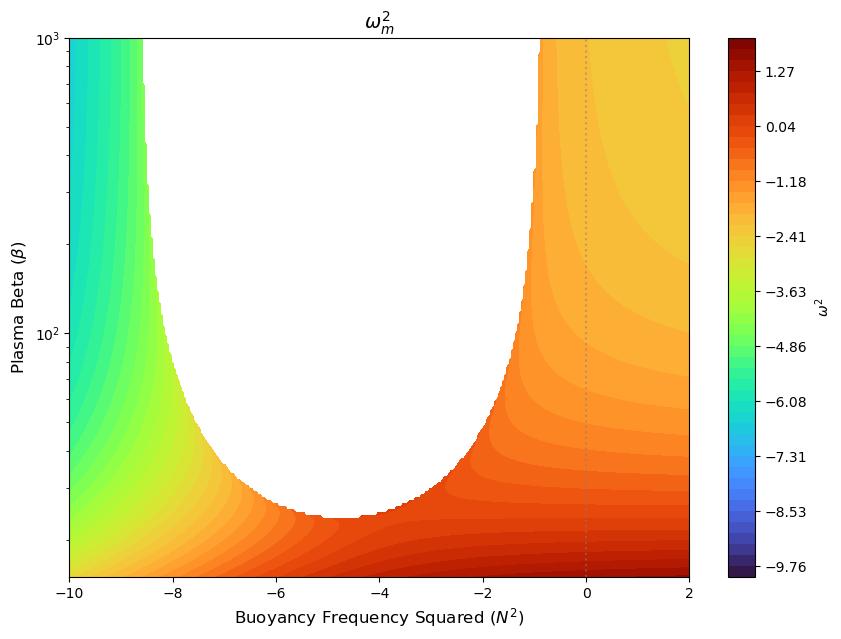

In [1]:

# 1. Fixed Parameters
q = 1.5
kz = 6.0
ky = 2.0 * kz
kx = 0.0  
k2 = kx**2 + ky**2 + kz**2

# 2. Create the Grid
# N2 from convectively unstable (-1.5) to stably stratified (1.5)
N2_vals = np.linspace(-10, 2, 300)
beta_vals = np.logspace(0, np.log10(1000), 300)
# beta_vals = np.linspace(0, 1000, 300)

N2_grid, beta_grid = np.meshgrid(N2_vals, beta_vals)

# 3. Calculate the Coefficients across the grid
a1 = (N2_grid * (ky**2 + kx**2) / k2 
      + 2 * (2 - q) * (kz**2) / k2 
      + 4 * kz**2 / beta_grid 
      - 2 * q * (ky**2) / k2)

a2 = (2 * q * N2_grid * (ky**2) / k2 
      - 4 * kz**4 / (beta_grid**2) 
      - (2 * kz**2 / beta_grid) * (N2_grid * (kx**2 + ky**2) / k2 - 2 * q * (ky**2 + kz**2) / k2))

# 4. Calculate w_m^2 AND w_g^2
discriminant = a1**2 + 4 * a2

# Mask out regions where roots become complex (overstability regime)
valid_discriminant = np.where(discriminant < 0, np.nan, discriminant)

w2_m = (a1 - np.sqrt(valid_discriminant)) / 2
w2_g = (a1 + np.sqrt(valid_discriminant)) / 2  # Adicionada a raiz superior!


# 5. Plotting
fig, ax = plt.subplots(figsize=(10, 7))

# Definimos níveis separados para cada raiz para melhor visualização
# w_m^2 geralmente abriga a instabilidade (valores negativos)
#levels_m = [-10,-5,-3 ,-2.0, -1.0, -0.5, 0.0]
levels_m = np.linspace(-10, 2)
levels_g = np.linspace(-10, 2)

# w_g^2 geralmente representa modos estáveis (valores positivos)
# levels_m = [-10,-5, -3, -2.0, -1.0, -0.5, 0.0]

# Plota w_m^2 (Linhas contínuas, mapa de cor 'viridis_r')
# contour_g = ax.contourf(N2_grid, beta_grid, w2_m - w2_g, levels=levels_m, cmap='viridis') #, linewidths=2, linestyles='solid')

contour_m = ax.contourf(N2_grid, beta_grid, w2_m, levels=levels_m, cmap='turbo', linewidths=2, linestyles='solid')

#contour_g = ax.contourf(N2_grid, beta_grid, w2_g, levels=levels_m, cmap='turbo', linewidths=2, linestyles='dashed')



# ax.clabel(contour_m, inline=True, fontsize=10, fmt=r'$\omega_m^2 = %1.1f$')

# Plota w_g^2 (Linhas tracejadas, mapa de cor 'plasma')
#contour_g = ax.contour(N2_grid, beta_grid, w2_g, levels=levels_g, 
#                       cmap='plasma', linewidths=2, linestyles='dashed')
#ax.clabel(contour_g, inline=True, fontsize=10, fmt=r'$\omega_g^2 = %1.1f$')

#plt.colorbar(contour_m)


cbar2 = plt.colorbar(contour_m)
cbar2.set_label(r'$\omega^2$')




# Formatting axes
ax.set_xlabel(r'Buoyancy Frequency Squared ($N^2$)', fontsize=12)
ax.set_ylabel(r'Plasma Beta ($\beta$)', fontsize=12)
ax.set_title(r'$\omega_m^2$', fontsize=14)

# Add a dashed reference line for neutral stratification (N^2 = 0)
ax.axvline(0, color='gray', linestyle=':', linewidth=1.5, alpha=0.5) 
# Growth rates from each branch


# ---------------------------------------------------------
# NOVO CÓDIGO: Plotar os 16 pontos do cruzamento dos arrays
# ---------------------------------------------------------
beta_pontos = np.array([130, 400, 650, 1000])
N2_pontos = np.array([0.5, -0.25, -0.75, -0.43])

# Criamos um grid com os pontos específicos
N2_pts_grid, beta_pts_grid = np.meshgrid(N2_pontos, beta_pontos)

#Plotamos os pontos (zorder=5 garante que fiquem acima das linhas de contorno)
#ax.scatter(N2_pts_grid, beta_pts_grid, color='red', edgecolor='black', 
#           s=60, zorder=5, label='Points of interest')

# Adicionamos a legenda para identificar os pontos
#ax.legend(loc='best')
# ---------------------------------------------------------

# Fill the complex/overstable region with a light gray so it's clearly distinct
#ax.set_facecolor('#f0f0f0')
#ax.set_yscale('log')
ax.set_ylim(15, 1000)
#ax.set_xlim(-1.5, 1.5)


# ax.tick_params(axis='both', direction='in', top=True, right=True)

plt.yscale('log')

# plt.xscale('log')
plt.show()